In [11]:
# Notebook 03 — Model Comparison: Reconstruction AE, Forecasting AE, AAE, Forecasting AAE
# Replicates omarWafaay's successful pipeline: chronological split, W=128, half-window forecasting (64→64)

import os
import sys
import copy
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve

# Setup paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT))

# Config - MATCH omarWafaay exactly
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Data / window parameters (EXACT from omarWafaay)
WINDOW_LEN = 128
FORECAST_HALF = WINDOW_LEN // 2       # 64 input / 64 target
STRIDE_TRAIN = 32                     # overlapping training windows
STRIDE_EVAL = 128                     # non-overlapping validation/test/slow windows
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
SLOW_VAL_FRAC = 0.50                  # slow_val chooses thresholds; slow_test is final eval

# Model / training (identical for both AEs)
ENC_CHANNELS = (64, 32)
BATCH_SIZE = 256
EPOCHS = 60
LEARNING_RATE = 1e-3
PATIENCE = 10
GRAD_CLIP = 1.0

# AAE hyperparameters
LR_G_AAE = 1e-3
LR_D_AAE = 1e-4
LAMBDA_ADV = 0.01
BETAS_AAE = (0.5, 0.999)

print(f"Device: {DEVICE}")
print(f"Config: W={WINDOW_LEN}, forecast_half={FORECAST_HALF}, enc_channels={ENC_CHANNELS}")
print(f"Train: stride={STRIDE_TRAIN}, Eval: stride={STRIDE_EVAL}")
print(f"AAE: lambda_adv={LAMBDA_ADV}, lr_G={LR_G_AAE}, lr_D={LR_D_AAE}")

Device: cpu
Config: W=128, forecast_half=64, enc_channels=(64, 32)
Train: stride=32, Eval: stride=128
AAE: lambda_adv=0.01, lr_G=0.001, lr_D=0.0001


In [12]:
# ============================================================
# DATA LOADING & PREPROCESSING (EXACT omarWafaay pipeline)
# ============================================================

DATA_FOLDER = PROJECT_ROOT / "data" / "raw"

# --- load + drop action -------------------------------------------------
kuka_normal = np.load(DATA_FOLDER / "KukaNormal.npy").astype(np.float32)
kuka_slow   = np.load(DATA_FOLDER / "KukaSlow.npy").astype(np.float32)

X_normal = kuka_normal[:, 1:]                  # drop column 0 ("action")
X_slow   = kuka_slow[:, :-1][:, 1:]            # drop "anomaly" label, drop "action"
n_features = X_normal.shape[1]
print(f"X_normal: {X_normal.shape}   X_slow: {X_slow.shape}   n_features: {n_features}")

# --- time-aware split on normal (chronological) -----------------------------------------
T = X_normal.shape[0]
nt = int(T * TRAIN_FRAC)
nv = int(T * VAL_FRAC)
train_raw = X_normal[:nt]
val_raw   = X_normal[nt:nt + nv]
test_raw  = X_normal[nt + nv:]
print(f"normal raw   train: {train_raw.shape}   val: {val_raw.shape}   test: {test_raw.shape}")

# --- min-max [-1, 1] with clip (fitted on train ONLY) ------------------------------------------
def fit_minmax(X, feature_range=(-1.0, 1.0), eps=1e-8):
    mn = X.min(axis=0).astype(np.float32)
    mx = X.max(axis=0).astype(np.float32)
    span = np.maximum(mx - mn, eps)
    lo, hi = feature_range
    a = ((hi - lo) / span).astype(np.float32)
    b = (lo - mn * a).astype(np.float32)
    return a, b

def apply_minmax(X, a, b, fr=(-1.0, 1.0)):
    return np.clip(X * a + b, fr[0], fr[1]).astype(np.float32)

a, b = fit_minmax(train_raw)
train_s = apply_minmax(train_raw, a, b)
val_s   = apply_minmax(val_raw,   a, b)
test_s  = apply_minmax(test_raw,  a, b)
slow_s  = apply_minmax(X_slow,    a, b)

# --- sliding windows (N, F, L) ------------------------------------------
def make_windows(x, window_len, stride):
    T = x.shape[0]
    n = (T - window_len) // stride + 1
    idx = np.arange(window_len)[None, :] + stride * np.arange(n)[:, None]
    return np.transpose(x[idx], (0, 2, 1)).astype(np.float32)        # (N, F, L)

W_train = torch.from_numpy(make_windows(train_s, WINDOW_LEN, STRIDE_TRAIN))
W_val   = torch.from_numpy(make_windows(val_s,   WINDOW_LEN, STRIDE_EVAL))
W_test  = torch.from_numpy(make_windows(test_s,  WINDOW_LEN, STRIDE_EVAL))

W_slow_all = torch.from_numpy(make_windows(slow_s, WINDOW_LEN, STRIDE_EVAL))
n_slow_val = int(len(W_slow_all) * SLOW_VAL_FRAC)
W_slow_val = W_slow_all[:n_slow_val].contiguous()
W_slow_test = W_slow_all[n_slow_val:].contiguous()

# Compatibility alias: existing evaluation cells treat W_slow as the untouched slow-test set.
W_slow = W_slow_test

print(f"\nwindows  train={tuple(W_train.shape)}  val_normal={tuple(W_val.shape)}  "
      f"test_normal={tuple(W_test.shape)}  slow_val={tuple(W_slow_val.shape)}  "
      f"slow_test={tuple(W_slow_test.shape)}")

# --- forecast pairs: first 64 = input, next 64 = target -----------------
def split_pair(X_BFL, h):
    return X_BFL[:, :, :h].contiguous(), X_BFL[:, :, h:h * 2].contiguous()

X_train_in, X_train_tg = split_pair(W_train, FORECAST_HALF)
X_val_in,   X_val_tg   = split_pair(W_val,   FORECAST_HALF)
X_test_in,  X_test_tg  = split_pair(W_test,  FORECAST_HALF)
X_slow_val_in, X_slow_val_tg   = split_pair(W_slow_val, FORECAST_HALF)
X_slow_test_in, X_slow_test_tg = split_pair(W_slow_test, FORECAST_HALF)

# DataLoaders
recon_train_loader = DataLoader(TensorDataset(W_train, W_train), batch_size=BATCH_SIZE, shuffle=True)
recon_val_loader   = DataLoader(TensorDataset(W_val,   W_val),   batch_size=BATCH_SIZE, shuffle=False)

forecast_train_loader = DataLoader(TensorDataset(X_train_in, X_train_tg), batch_size=BATCH_SIZE, shuffle=True)
forecast_val_loader   = DataLoader(TensorDataset(X_val_in,   X_val_tg),   batch_size=BATCH_SIZE, shuffle=False)

# For AAE: slow_val is used for threshold selection, slow_test for final eval
# We also need a fusion training split from val_normal (half for AAE fusion training)
# But for now, just standard loaders
print("\nDataLoaders created:")
print(f"  recon_train: {len(recon_train_loader)} batches")
print(f"  forecast_train: {len(forecast_train_loader)} batches")

X_normal: (233792, 85)   X_slow: (41538, 85)   n_features: 85
normal raw   train: (163654, 85)   val: (35068, 85)   test: (35070, 85)

windows  train=(5111, 85, 128)  val_normal=(273, 85, 128)  test_normal=(273, 85, 128)  slow_val=(162, 85, 128)  slow_test=(162, 85, 128)

DataLoaders created:
  recon_train: 20 batches
  forecast_train: 20 batches


In [13]:
# ============================================================
# MODEL ARCHITECTURES (EXACT from omarWafaay)
# ============================================================

class ConvAE1D(nn.Module):
    """Core ConvAE1D from omarWafaay - 2 pooling layers, Tanh output"""
    def __init__(self, n_features, enc_channels=(64, 32)):
        super().__init__()
        c1, c2 = enc_channels
        self.encoder = nn.Sequential(
            nn.Conv1d(n_features, c1, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool1d(2),
            nn.Conv1d(c1, c2, 3, padding=1),         nn.ReLU(inplace=True), nn.MaxPool1d(2),
        )
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv1d(c2, c2, 3, padding=1), nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv1d(c2, c1, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv1d(c1, n_features, 3, padding=1),
            nn.Tanh(),
        )

    def encode(self, x): return self.encoder(x)
    def decode(self, z): return self.decoder(z)
    def forward(self, x): return self.decode(self.encode(x))


class Discriminator1D(nn.Module):
    """Discriminator from omarWafaay - spectral norm, stride-2 convs, hinge loss"""
    def __init__(self, n_features, hidden_channels=(32, 64, 128), input_len=128, neg_slope=0.2):
        super().__init__()
        layers = []
        in_c = n_features
        for i, c in enumerate(hidden_channels):
            layers.append(nn.utils.parametrizations.spectral_norm(
                nn.Conv1d(in_c, c, kernel_size=4, stride=2, padding=1)
            ))
            if i > 0:                                  # no BN on layer 0
                layers.append(nn.BatchNorm1d(c))
            layers.append(nn.LeakyReLU(neg_slope, inplace=True))
            in_c = c
        self.conv = nn.Sequential(*layers)
        flat_len = (input_len // (2 ** len(hidden_channels))) * hidden_channels[-1]
        self.fc = nn.utils.parametrizations.spectral_norm(nn.Linear(flat_len, 1))

    def forward(self, x):
        z = self.conv(x).flatten(1)
        return self.fc(z).squeeze(-1)                  # (B,) linear score


def hinge_loss_D(d_real, d_fake):
    return F.relu(1.0 - d_real).mean() + F.relu(1.0 + d_fake).mean()

def hinge_loss_G(d_fake):
    return -d_fake.mean()


# ============================================================
# MODEL 1: RECONSTRUCTION AE
# ============================================================
recon_model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
n_params_recon = sum(p.numel() for p in recon_model.parameters())
print(f"Reconstruction AE params: {n_params_recon:,}")
print(f"  Encoder: {sum(p.numel() for p in recon_model.encoder.parameters()):,}")
print(f"  Decoder: {sum(p.numel() for p in recon_model.decoder.parameters()):,}")

# ============================================================
# MODEL 2: FORECASTING AE (half-window: 64 -> 64)
# ============================================================
# Uses SAME ConvAE1D architecture but on half-window
forecast_model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
n_params_forecast = sum(p.numel() for p in forecast_model.parameters())
print(f"\nForecasting AE params: {n_params_forecast:,} (same architecture, applied to 64-step windows)")

# ============================================================
# MODEL 3: AAE (Reconstruction + Adversarial)
# ============================================================
aae_model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
aae_discriminator = Discriminator1D(n_features=n_features, input_len=WINDOW_LEN).to(DEVICE)
n_params_aae = sum(p.numel() for p in aae_model.parameters())
n_params_aae_d = sum(p.numel() for p in aae_discriminator.parameters())
print(f"\nAAE params: G={n_params_aae:,}  D={n_params_aae_d:,}  lambda_adv={LAMBDA_ADV}")

# ============================================================
# MODEL 4: FORECASTING AAE (Forecasting + Adversarial)
# ============================================================
fc_aae_model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
fc_aae_discriminator = Discriminator1D(n_features=n_features, input_len=FORECAST_HALF).to(DEVICE)
n_params_fc_aae = sum(p.numel() for p in fc_aae_model.parameters())
n_params_fc_aae_d = sum(p.numel() for p in fc_aae_discriminator.parameters())
print(f"\nForecasting AAE params: G={n_params_fc_aae:,}  D={n_params_fc_aae_d:,}  lambda_adv={LAMBDA_ADV}")

Reconstruction AE params: 48,277
  Encoder: 22,560
  Decoder: 25,717

Forecasting AE params: 48,277 (same architecture, applied to 64-step windows)

AAE params: G=48,277  D=54,497  lambda_adv=0.01

Forecasting AAE params: G=48,277  D=53,473  lambda_adv=0.01


In [14]:
# ============================================================
# TRAINING UTILITIES
# ============================================================

def run_epoch(model, loader, loss_fn, device, optimizer=None, grad_clip=None):
    """Run one epoch of training or evaluation."""
    is_train = optimizer is not None
    model.train(is_train)
    total, n = 0.0, 0
    for xi, xt in loader:
        xi = xi.to(device, non_blocking=True)
        xt = xt.to(device, non_blocking=True)
        loss = loss_fn(model(xi), xt)
        if is_train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            if grad_clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
        total += loss.item() * xi.size(0)
        n += xi.size(0)
    return total / max(n, 1)


def train_recon_ae(model, train_loader, val_loader, *, tag="Recon AE", seed=42):
    """Train standard reconstruction AE with early stopping on val MSE."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()

    train_losses, val_losses = [], []
    best_val, best_state, remaining = float("inf"), None, PATIENCE

    for epoch in range(1, EPOCHS + 1):
        tr = run_epoch(model, train_loader, loss_fn, DEVICE, optimizer, GRAD_CLIP)
        with torch.no_grad():
            va = run_epoch(model, val_loader, loss_fn, DEVICE, optimizer=None)
        train_losses.append(tr); val_losses.append(va)
        improved = va < best_val - 1e-6
        if improved:
            best_val = va
            best_state = copy.deepcopy(model.state_dict())
            remaining = PATIENCE
        print(f"  [{tag}] epoch {epoch:03d} | train {tr:.6f} | val {va:.6f}{' *' if improved else ''}")
        if not improved:
            remaining -= 1
            if remaining <= 0:
                print(f"  [{tag}] Early stop at epoch {epoch} (best val {best_val:.6f})")
                break

    model.load_state_dict(best_state)
    return model, train_losses, val_losses, best_val


def train_forecast_ae(model, train_loader, val_loader, *, tag="Forecast AE", seed=42):
    """Train forecasting AE (64->64) with early stopping on val MSE."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()

    train_losses, val_losses = [], []
    best_val, best_state, remaining = float("inf"), None, PATIENCE

    for epoch in range(1, EPOCHS + 1):
        tr = run_epoch(model, train_loader, loss_fn, DEVICE, optimizer, GRAD_CLIP)
        with torch.no_grad():
            va = run_epoch(model, val_loader, loss_fn, DEVICE, optimizer=None)
        train_losses.append(tr); val_losses.append(va)
        improved = va < best_val - 1e-6
        if improved:
            best_val = va
            best_state = copy.deepcopy(model.state_dict())
            remaining = PATIENCE
        print(f"  [{tag}] epoch {epoch:03d} | train {tr:.6f} | val {va:.6f}{' *' if improved else ''}")
        if not improved:
            remaining -= 1
            if remaining <= 0:
                print(f"  [{tag}] Early stop at epoch {epoch} (best val {best_val:.6f})")
                break

    model.load_state_dict(best_state)
    return model, train_losses, val_losses, best_val


def train_aae(model, discriminator, train_loader, val_loader, *, tag="AAE", seed=42):
    """Train AAE (reconstruction + adversarial) with early stopping on val MSE."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
    D = Discriminator1D(n_features=n_features, input_len=WINDOW_LEN).to(DEVICE)

    opt_G = torch.optim.Adam(model.parameters(), lr=LR_G_AAE, betas=BETAS_AAE)
    opt_D = torch.optim.Adam(D.parameters(), lr=LR_D_AAE, betas=BETAS_AAE)
    mse = nn.MSELoss()

    hist = {"train_mse": [], "val_mse": [], "loss_D": [], "loss_G_adv": [], "d_real": [], "d_fake": []}
    best_val, best_state, remaining = float("inf"), None, PATIENCE

    for epoch in range(1, EPOCHS + 1):
        model.train(); D.train()
        sums = {k: 0.0 for k in ("mse", "lD", "lGadv", "dreal", "dfake")}
        n_seen = 0
        for (x_real, _) in train_loader:
            x_real = x_real.to(DEVICE, non_blocking=True)
            batch_size = x_real.size(0)

            # ---- D step --------------------------------------------------
            opt_D.zero_grad(set_to_none=True)
            with torch.no_grad():
                x_fake_d = model(x_real)
            d_real = D(x_real)
            d_fake = D(x_fake_d)
            loss_D = hinge_loss_D(d_real, d_fake)
            loss_D.backward()
            opt_D.step()

            # ---- G step --------------------------------------------------
            opt_G.zero_grad(set_to_none=True)
            x_fake = model(x_real)
            mse_loss = mse(x_fake, x_real)
            adv_loss_G = hinge_loss_G(D(x_fake))
            loss_G = mse_loss + LAMBDA_ADV * adv_loss_G
            loss_G.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt_G.step()

            bs = x_real.size(0); n_seen += bs
            sums["mse"]    += mse_loss.item()   * bs
            sums["lD"]     += loss_D.item()     * bs
            sums["lGadv"]  += adv_loss_G.item() * bs
            sums["dreal"]  += d_real.mean().item() * bs
            sums["dfake"]  += d_fake.mean().item() * bs

        tr_mse = sums["mse"] / n_seen
        tr_lD = sums["lD"] / n_seen
        tr_lGadv = sums["lGadv"] / n_seen

        # ---- val (MSE only) ---------------------------------------------
        model.eval()
        with torch.no_grad():
            tot, n = 0.0, 0
            for (xv, _) in val_loader:
                xv = xv.to(DEVICE, non_blocking=True)
                tot += mse(model(xv), xv).item() * xv.size(0); n += xv.size(0)
            va_mse = tot / max(n, 1)

        hist["train_mse"].append(tr_mse); hist["val_mse"].append(va_mse)
        hist["loss_D"].append(tr_lD); hist["loss_G_adv"].append(tr_lGadv)
        hist["d_real"].append(sums["dreal"] / n_seen); hist["d_fake"].append(sums["dfake"] / n_seen)

        improved = va_mse < best_val - 1e-6
        if improved:
            best_val = va_mse
            best_state = copy.deepcopy(model.state_dict())
            remaining = PATIENCE
        print(f"  [{tag}] epoch {epoch:03d} | train MSE {tr_mse:.6f} | val MSE {va_mse:.6f}{' *' if improved else ''}")
        if not improved:
            remaining -= 1
            if remaining <= 0:
                print(f"  [{tag}] Early stop at epoch {epoch} (best val {best_val:.6f})")
                break

    model.load_state_dict(best_state)
    return model, D, hist, best_val


def train_forecast_aae(model, discriminator, train_loader, val_loader, *, tag="Forecast AAE", seed=42):
    """Train Forecasting AAE (64->64 + adversarial on future windows)."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = ConvAE1D(n_features=n_features, enc_channels=ENC_CHANNELS).to(DEVICE)
    D = Discriminator1D(n_features=n_features, input_len=FORECAST_HALF).to(DEVICE)

    opt_G = torch.optim.Adam(model.parameters(), lr=LR_G_AAE, betas=BETAS_AAE)
    opt_D = torch.optim.Adam(D.parameters(), lr=LR_D_AAE, betas=BETAS_AAE)
    mse = nn.MSELoss()

    hist = {"train_mse": [], "val_mse": [], "loss_D": [], "loss_G_adv": [], "d_real": [], "d_fake": []}
    best_val, best_state, remaining = float("inf"), None, PATIENCE

    for epoch in range(1, EPOCHS + 1):
        model.train(); D.train()
        sums = {k: 0.0 for k in ("mse", "lD", "lGadv", "dreal", "dfake")}
        n_seen = 0
        for x_past, x_future in train_loader:
            x_past = x_past.to(DEVICE, non_blocking=True)
            x_future = x_future.to(DEVICE, non_blocking=True)
            batch_size = x_past.size(0)

            # D step: real future windows vs generated future windows
            opt_D.zero_grad(set_to_none=True)
            with torch.no_grad():
                x_fake_d = model(x_past)
            d_real = D(x_future)
            d_fake = D(x_fake_d)
            loss_D = hinge_loss_D(d_real, d_fake)
            loss_D.backward()
            opt_D.step()

            # G step: forecast MSE + adversarial future-window realism
            opt_G.zero_grad(set_to_none=True)
            x_fake = model(x_past)
            mse_loss = mse(x_fake, x_future)
            adv_loss_G = hinge_loss_G(D(x_fake))
            loss_G = mse_loss + LAMBDA_ADV * adv_loss_G
            loss_G.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt_G.step()

            bs = x_past.size(0); n_seen += bs
            sums["mse"]   += mse_loss.item()   * bs
            sums["lD"]    += loss_D.item()     * bs
            sums["lGadv"] += adv_loss_G.item() * bs
            sums["dreal"] += d_real.mean().item() * bs
            sums["dfake"] += d_fake.mean().item() * bs

        tr_mse = sums["mse"] / n_seen
        tr_lD = sums["lD"] / n_seen
        tr_lGadv = sums["lGadv"] / n_seen

        # ---- val (MSE only) ---------------------------------------------
        model.eval()
        with torch.no_grad():
            tot, n = 0.0, 0
            for xv_past, xv_future in val_loader:
                xv_past = xv_past.to(DEVICE, non_blocking=True)
                xv_future = xv_future.to(DEVICE, non_blocking=True)
                tot += mse(model(xv_past), xv_future).item() * xv_past.size(0); n += xv_past.size(0)
            va_mse = tot / max(n, 1)

        hist["train_mse"].append(tr_mse); hist["val_mse"].append(va_mse)
        hist["loss_D"].append(tr_lD); hist["loss_G_adv"].append(tr_lGadv)
        hist["d_real"].append(sums["dreal"] / n_seen); hist["d_fake"].append(sums["dfake"] / n_seen)

        improved = va_mse < best_val - 1e-6
        if improved:
            best_val = va_mse
            best_state = copy.deepcopy(model.state_dict())
            remaining = PATIENCE
        print(f"  [{tag}] epoch {epoch:03d} | train MSE {tr_mse:.6f} | val MSE {va_mse:.6f}{' *' if improved else ''}")
        if not improved:
            remaining -= 1
            if remaining <= 0:
                print(f"  [{tag}] Early stop at epoch {epoch} (best val {best_val:.6f})")
                break

    model.load_state_dict(best_state)
    return model, D, hist, best_val

In [15]:
# ============================================================
# EVALUATION UTILITIES
# ============================================================

@torch.no_grad()
def compute_recon_errors(model, loader, device):
    """Compute per-window reconstruction MSE for anomaly scoring."""
    model.eval()
    errors = []
    for (x, _) in loader:
        x = x.to(device, non_blocking=True)
        x_hat = model(x)
        # Per-window MSE: mean over features and time
        err = F.mse_loss(x_hat, x, reduction='none').mean(dim=(1, 2))
        errors.append(err.cpu())
    return torch.cat(errors).numpy()


@torch.no_grad()
def compute_forecast_errors(model, loader, device):
    """Compute per-window forecast MSE for anomaly scoring."""
    model.eval()
    errors = []
    for x_past, x_future in loader:
        x_past = x_past.to(device, non_blocking=True)
        x_future = x_future.to(device, non_blocking=True)
        x_fake = model(x_past)
        # Per-window forecast MSE: mean over features and time (64 steps)
        err = F.mse_loss(x_fake, x_future, reduction='none').mean(dim=(1, 2))
        errors.append(err.cpu())
    return torch.cat(errors).numpy()


def evaluate_model(model, normal_loader, anomaly_loader, device, mode='reconstruction'):
    """Evaluate model on normal and anomaly data, return errors."""
    if mode == 'reconstruction':
        norm_err = compute_recon_errors(model, normal_loader, device)
        anom_err = compute_recon_errors(model, anomaly_loader, device)
    elif mode == 'forecasting':
        norm_err = compute_forecast_errors(model, normal_loader, device)
        anom_err = compute_forecast_errors(model, anomaly_loader, device)
    else:
        raise ValueError(f"Unknown mode: {mode}")
    return norm_err, anom_err


def compute_metrics(norm_err, anom_err, threshold=None):
    """Compute ROC-AUC, PR-AUC, and optionally F1 at given threshold."""
    y_true = np.concatenate([np.zeros(len(norm_err)), np.ones(len(anom_err))])
    y_score = np.concatenate([norm_err, anom_err])
    
    roc_auc = roc_auc_score(y_true, y_score)
    pr_auc = average_precision_score(y_true, y_score)
    
    result = {"roc_auc": roc_auc, "pr_auc": pr_auc}
    
    if threshold is not None:
        y_pred = (y_score > threshold).astype(int)
        f1 = f1_score(y_true, y_pred)
        result["f1"] = f1
        result["threshold"] = threshold
    
    return result


def percentile_threshold_selection(val_norm_err, val_anom_err, percentiles=(80, 85, 90, 95, 97, 99)):
    """Select best percentile threshold using validation anomaly data (semi-supervised)."""
    val_labels = np.concatenate([np.zeros(len(val_norm_err)), np.ones(len(val_anom_err))])
    val_scores = np.concatenate([val_norm_err, val_anom_err])
    
    best_f1 = -1
    best_thresh = None
    best_p = None
    
    for p in percentiles:
        thresh = np.percentile(val_norm_err, p)
        pred = (val_scores > thresh).astype(int)
        f1 = f1_score(val_labels, pred)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = thresh
            best_p = p
    
    return best_thresh, best_p, best_f1


def mu_sigma_threshold(val_norm_err, k=2):
    """Classic mu + k*sigma threshold on normal validation errors (unsupervised)."""
    mu = val_norm_err.mean()
    sigma = val_norm_err.std()
    return mu + k * sigma


print("Evaluation utilities ready.")

Evaluation utilities ready.


RECONSTRUCTION AE
  [Recon AE] epoch 001 | train 0.174713 | val 0.118910 *
  [Recon AE] epoch 002 | train 0.105592 | val 0.103379 *
  [Recon AE] epoch 003 | train 0.078008 | val 0.085331 *
  [Recon AE] epoch 004 | train 0.056597 | val 0.070628 *
  [Recon AE] epoch 005 | train 0.043073 | val 0.062263 *
  [Recon AE] epoch 006 | train 0.032878 | val 0.050923 *
  [Recon AE] epoch 007 | train 0.025123 | val 0.044580 *
  [Recon AE] epoch 008 | train 0.022327 | val 0.041715 *
  [Recon AE] epoch 009 | train 0.020635 | val 0.038742 *
  [Recon AE] epoch 010 | train 0.019594 | val 0.036620 *
  [Recon AE] epoch 011 | train 0.018475 | val 0.034910 *
  [Recon AE] epoch 012 | train 0.017835 | val 0.034656 *
  [Recon AE] epoch 013 | train 0.016785 | val 0.033546 *
  [Recon AE] epoch 014 | train 0.016184 | val 0.032448 *
  [Recon AE] epoch 015 | train 0.015409 | val 0.031720 *
  [Recon AE] epoch 016 | train 0.014908 | val 0.030911 *
  [Recon AE] epoch 017 | train 0.014412 | val 0.029626 *
  [Recon AE] 

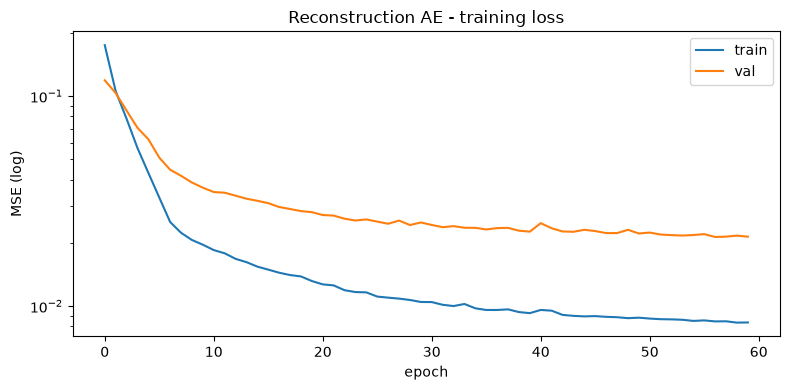


Evaluating on validation...

Validation: ROC-AUC=0.0104, PR-AUC=0.2164
Test:       ROC-AUC=0.9565, PR-AUC=0.9550

Thresholds:
  mu+2sigma: 0.031716
  Best percentile p80: 0.025696 (val F1=0.0000)

Test F1 @ mu+2sigma: 0.7344
Test F1 @ p80: 0.9115


In [16]:
# ============================================================
# TRAIN & EVALUATE: RECONSTRUCTION AE
# ============================================================
print("=" * 60)
print("RECONSTRUCTION AE")
print("=" * 60)

recon_model, recon_tr_losses, recon_va_losses, recon_best_val = train_recon_ae(
    None, recon_train_loader, recon_val_loader, tag="Recon AE", seed=SEED
)

# Save checkpoint
torch.save({
    "model_state": recon_model.state_dict(),
    "train_losses": recon_tr_losses, "val_losses": recon_va_losses,
    "config": {"window_len": WINDOW_LEN, "objective": "reconstruction",
               "enc_channels": list(ENC_CHANNELS), "batch_size": BATCH_SIZE,
               "lr": LEARNING_RATE, "epochs_run": len(recon_tr_losses),
               "best_val": recon_best_val}
}, PROJECT_ROOT / "recon_ae.pt")
print("Saved -> recon_ae.pt")

# Plot training curves
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(recon_tr_losses, label="train")
ax.plot(recon_va_losses, label="val")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (log)")
ax.set_title("Reconstruction AE - training loss")
ax.legend()
plt.tight_layout()
plt.show()

# Evaluate on validation (normal + anomaly) for metrics
print("\nEvaluating on validation...")
recon_val_norm_err, recon_val_anom_err = evaluate_model(
    recon_model, recon_val_loader, 
    DataLoader(TensorDataset(W_slow_val, W_slow_val), batch_size=BATCH_SIZE, shuffle=False),
    DEVICE, mode='reconstruction'
)

recon_test_norm_err, recon_test_anom_err = evaluate_model(
    recon_model, 
    DataLoader(TensorDataset(W_test, W_test), batch_size=BATCH_SIZE, shuffle=False),
    DataLoader(TensorDataset(W_slow_test, W_slow_test), batch_size=BATCH_SIZE, shuffle=False),
    DEVICE, mode='reconstruction'
)

# Metrics
recon_val_metrics = compute_metrics(recon_val_norm_err, recon_val_anom_err)
recon_test_metrics = compute_metrics(recon_test_norm_err, recon_test_anom_err)

print(f"\nValidation: ROC-AUC={recon_val_metrics['roc_auc']:.4f}, PR-AUC={recon_val_metrics['pr_auc']:.4f}")
print(f"Test:       ROC-AUC={recon_test_metrics['roc_auc']:.4f}, PR-AUC={recon_test_metrics['pr_auc']:.4f}")

# Threshold selection (semi-supervised: use val_normal + val_anomaly)
recon_thresh_pct, recon_best_p, recon_best_f1 = percentile_threshold_selection(
    recon_val_norm_err, recon_val_anom_err
)
recon_thresh_mu2 = mu_sigma_threshold(recon_val_norm_err)

print(f"\nThresholds:")
print(f"  mu+2sigma: {recon_thresh_mu2:.6f}")
print(f"  Best percentile p{recon_best_p}: {recon_thresh_pct:.6f} (val F1={recon_best_f1:.4f})")

# Test with selected thresholds
recon_test_mu2 = compute_metrics(recon_test_norm_err, recon_test_anom_err, recon_thresh_mu2)
recon_test_pct = compute_metrics(recon_test_norm_err, recon_test_anom_err, recon_thresh_pct)

print(f"\nTest F1 @ mu+2sigma: {recon_test_mu2['f1']:.4f}")
print(f"Test F1 @ p{recon_best_p}: {recon_test_pct['f1']:.4f}")

# Store results
recon_results = {
    "tag": "Reconstruction AE",
    "val_roc_auc": recon_val_metrics['roc_auc'],
    "val_pr_auc": recon_val_metrics['pr_auc'],
    "test_roc_auc": recon_test_metrics['roc_auc'],
    "test_pr_auc": recon_test_metrics['pr_auc'],
    "threshold_mu2": recon_thresh_mu2,
    "threshold_pct": recon_thresh_pct,
    "best_p": recon_best_p,
    "test_f1_mu2": recon_test_mu2['f1'],
    "test_f1_pct": recon_test_pct['f1'],
}

FORECASTING AE (64 -> 64)
  [Forecast AE] epoch 001 | train 0.176331 | val 0.121798 *
  [Forecast AE] epoch 002 | train 0.109258 | val 0.110801 *
  [Forecast AE] epoch 003 | train 0.088052 | val 0.101672 *
  [Forecast AE] epoch 004 | train 0.071206 | val 0.088663 *
  [Forecast AE] epoch 005 | train 0.056435 | val 0.077360 *
  [Forecast AE] epoch 006 | train 0.045011 | val 0.068870 *
  [Forecast AE] epoch 007 | train 0.039522 | val 0.060934 *
  [Forecast AE] epoch 008 | train 0.037134 | val 0.060664 *
  [Forecast AE] epoch 009 | train 0.035895 | val 0.058902 *
  [Forecast AE] epoch 010 | train 0.034599 | val 0.055823 *
  [Forecast AE] epoch 011 | train 0.033641 | val 0.056108
  [Forecast AE] epoch 012 | train 0.032694 | val 0.053881 *
  [Forecast AE] epoch 013 | train 0.031927 | val 0.053053 *
  [Forecast AE] epoch 014 | train 0.031271 | val 0.051060 *
  [Forecast AE] epoch 015 | train 0.030505 | val 0.049307 *
  [Forecast AE] epoch 016 | train 0.029950 | val 0.049219 *
  [Forecast AE] 

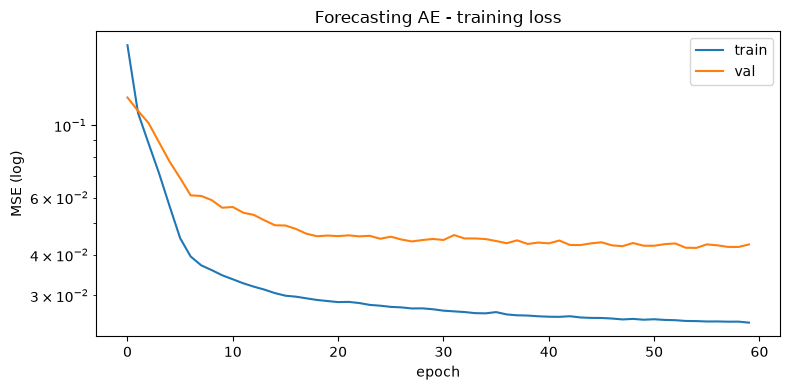


Evaluating on validation...

Validation: ROC-AUC=0.3492, PR-AUC=0.3089
Test:       ROC-AUC=0.9647, PR-AUC=0.9561

Thresholds:
  mu+2sigma: 0.066916
  Best percentile p80: 0.048008 (val F1=0.2429)

Test F1 @ mu+2sigma: 0.8936
Test F1 @ p80: 0.7731


In [17]:
# ============================================================
# TRAIN & EVALUATE: FORECASTING AE (64 -> 64)
# ============================================================
print("=" * 60)
print("FORECASTING AE (64 -> 64)")
print("=" * 60)

forecast_model, fc_tr_losses, fc_va_losses, fc_best_val = train_forecast_ae(
    None, forecast_train_loader, forecast_val_loader, tag="Forecast AE", seed=SEED
)

# Save checkpoint
torch.save({
    "model_state": forecast_model.state_dict(),
    "train_losses": fc_tr_losses, "val_losses": fc_va_losses,
    "config": {"window_len": WINDOW_LEN, "forecast_half": FORECAST_HALF,
               "objective": "forecasting", "enc_channels": list(ENC_CHANNELS),
               "batch_size": BATCH_SIZE, "lr": LEARNING_RATE,
               "epochs_run": len(fc_tr_losses), "best_val": fc_best_val}
}, PROJECT_ROOT / "forecast_ae.pt")
print("Saved -> forecast_ae.pt")

# Plot training curves
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fc_tr_losses, label="train")
ax.plot(fc_va_losses, label="val")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (log)")
ax.set_title("Forecasting AE - training loss")
ax.legend()
plt.tight_layout()
plt.show()

# Evaluate on validation
print("\nEvaluating on validation...")
# Create forecasting val loaders for slow_val
fc_slow_val_loader = DataLoader(TensorDataset(X_slow_val_in, X_slow_val_tg), batch_size=BATCH_SIZE, shuffle=False)
fc_slow_test_loader = DataLoader(TensorDataset(X_slow_test_in, X_slow_test_tg), batch_size=BATCH_SIZE, shuffle=False)

fc_val_norm_err, fc_val_anom_err = evaluate_model(
    forecast_model, forecast_val_loader, fc_slow_val_loader, DEVICE, mode='forecasting'
)

fc_test_norm_err, fc_test_anom_err = evaluate_model(
    forecast_model, 
    DataLoader(TensorDataset(X_test_in, X_test_tg), batch_size=BATCH_SIZE, shuffle=False),
    fc_slow_test_loader, DEVICE, mode='forecasting'
)

# Metrics
fc_val_metrics = compute_metrics(fc_val_norm_err, fc_val_anom_err)
fc_test_metrics = compute_metrics(fc_test_norm_err, fc_test_anom_err)

print(f"\nValidation: ROC-AUC={fc_val_metrics['roc_auc']:.4f}, PR-AUC={fc_val_metrics['pr_auc']:.4f}")
print(f"Test:       ROC-AUC={fc_test_metrics['roc_auc']:.4f}, PR-AUC={fc_test_metrics['pr_auc']:.4f}")

# Threshold selection (semi-supervised)
fc_thresh_pct, fc_best_p, fc_best_f1 = percentile_threshold_selection(fc_val_norm_err, fc_val_anom_err)
fc_thresh_mu2 = mu_sigma_threshold(fc_val_norm_err)

print(f"\nThresholds:")
print(f"  mu+2sigma: {fc_thresh_mu2:.6f}")
print(f"  Best percentile p{fc_best_p}: {fc_thresh_pct:.6f} (val F1={fc_best_f1:.4f})")

# Test with selected thresholds
fc_test_mu2 = compute_metrics(fc_test_norm_err, fc_test_anom_err, fc_thresh_mu2)
fc_test_pct = compute_metrics(fc_test_norm_err, fc_test_anom_err, fc_thresh_pct)

print(f"\nTest F1 @ mu+2sigma: {fc_test_mu2['f1']:.4f}")
print(f"Test F1 @ p{fc_best_p}: {fc_test_pct['f1']:.4f}")

# Store results
forecast_results = {
    "tag": "Forecasting AE",
    "val_roc_auc": fc_val_metrics['roc_auc'],
    "val_pr_auc": fc_val_metrics['pr_auc'],
    "test_roc_auc": fc_test_metrics['roc_auc'],
    "test_pr_auc": fc_test_metrics['pr_auc'],
    "threshold_mu2": fc_thresh_mu2,
    "threshold_pct": fc_thresh_pct,
    "best_p": fc_best_p,
    "test_f1_mu2": fc_test_mu2['f1'],
    "test_f1_pct": fc_test_pct['f1'],
}

AAE (Reconstruction + Adversarial)
  [AAE] epoch 001 | train MSE 0.172251 | val MSE 0.118876 *
  [AAE] epoch 002 | train MSE 0.100218 | val MSE 0.103745 *
  [AAE] epoch 003 | train MSE 0.076061 | val MSE 0.094304 *
  [AAE] epoch 004 | train MSE 0.060631 | val MSE 0.083658 *
  [AAE] epoch 005 | train MSE 0.050536 | val MSE 0.066696 *
  [AAE] epoch 006 | train MSE 0.041626 | val MSE 0.058512 *
  [AAE] epoch 007 | train MSE 0.036474 | val MSE 0.056464 *
  [AAE] epoch 008 | train MSE 0.030019 | val MSE 0.048373 *
  [AAE] epoch 009 | train MSE 0.028300 | val MSE 0.047847 *
  [AAE] epoch 010 | train MSE 0.026478 | val MSE 0.042447 *
  [AAE] epoch 011 | train MSE 0.025103 | val MSE 0.041964 *
  [AAE] epoch 012 | train MSE 0.025188 | val MSE 0.041670 *
  [AAE] epoch 013 | train MSE 0.025259 | val MSE 0.039321 *
  [AAE] epoch 014 | train MSE 0.023347 | val MSE 0.038363 *
  [AAE] epoch 015 | train MSE 0.023133 | val MSE 0.042379
  [AAE] epoch 016 | train MSE 0.023873 | val MSE 0.036366 *
  [AAE]

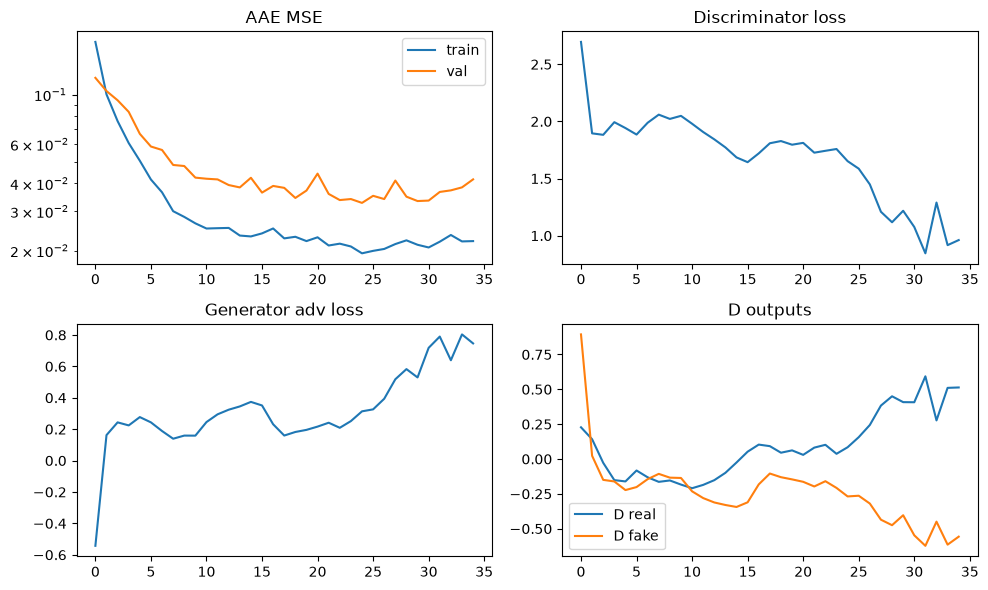


Evaluating on validation...

Validation: ROC-AUC=0.0057, PR-AUC=0.2161
Test:       ROC-AUC=0.9454, PR-AUC=0.9518

Thresholds:
  mu+2sigma: 0.041124
  Best percentile p80: 0.036315 (val F1=0.0000)

Test F1 @ mu+2sigma: 0.9385
Test F1 @ p80: 0.8902


In [18]:
# ============================================================
# TRAIN & EVALUATE: AAE (Reconstruction + Adversarial)
# ============================================================
print("=" * 60)
print("AAE (Reconstruction + Adversarial)")
print("=" * 60)

aae_model, aae_disc, aae_hist, aae_best_val = train_aae(
    None, None, recon_train_loader, recon_val_loader, tag="AAE", seed=SEED
)

# Save checkpoint
torch.save({
    "model_state": aae_model.state_dict(),
    "discriminator_state": aae_disc.state_dict(),
    "history": aae_hist,
    "config": {"window_len": WINDOW_LEN, "objective": "reconstruction_aae",
               "enc_channels": list(ENC_CHANNELS), "batch_size": BATCH_SIZE,
               "lr_G": LR_G_AAE, "lr_D": LR_D_AAE, "lambda_adv": LAMBDA_ADV,
               "betas": list(BETAS_AAE), "epochs_run": len(aae_hist["train_mse"]),
               "best_val": aae_best_val}
}, PROJECT_ROOT / "aae.pt")
print("Saved -> aae.pt")

# Plot training curves
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()
axes[0].plot(aae_hist["train_mse"], label="train"); axes[0].plot(aae_hist["val_mse"], label="val")
axes[0].set_yscale("log"); axes[0].set_title("AAE MSE"); axes[0].legend()
axes[1].plot(aae_hist["loss_D"], label="D loss"); axes[1].set_title("Discriminator loss")
axes[2].plot(aae_hist["loss_G_adv"], label="G adv"); axes[2].set_title("Generator adv loss")
axes[3].plot(aae_hist["d_real"], label="D real"); axes[3].plot(aae_hist["d_fake"], label="D fake")
axes[3].set_title("D outputs"); axes[3].legend()
plt.tight_layout()
plt.show()

# Evaluate on validation
print("\nEvaluating on validation...")
aae_val_norm_err, aae_val_anom_err = evaluate_model(
    aae_model, recon_val_loader,
    DataLoader(TensorDataset(W_slow_val, W_slow_val), batch_size=BATCH_SIZE, shuffle=False),
    DEVICE, mode='reconstruction'
)

aae_test_norm_err, aae_test_anom_err = evaluate_model(
    aae_model,
    DataLoader(TensorDataset(W_test, W_test), batch_size=BATCH_SIZE, shuffle=False),
    DataLoader(TensorDataset(W_slow_test, W_slow_test), batch_size=BATCH_SIZE, shuffle=False),
    DEVICE, mode='reconstruction'
)

# Metrics
aae_val_metrics = compute_metrics(aae_val_norm_err, aae_val_anom_err)
aae_test_metrics = compute_metrics(aae_test_norm_err, aae_test_anom_err)

print(f"\nValidation: ROC-AUC={aae_val_metrics['roc_auc']:.4f}, PR-AUC={aae_val_metrics['pr_auc']:.4f}")
print(f"Test:       ROC-AUC={aae_test_metrics['roc_auc']:.4f}, PR-AUC={aae_test_metrics['pr_auc']:.4f}")

# Threshold selection
aae_thresh_pct, aae_best_p, aae_best_f1 = percentile_threshold_selection(aae_val_norm_err, aae_val_anom_err)
aae_thresh_mu2 = mu_sigma_threshold(aae_val_norm_err)

print(f"\nThresholds:")
print(f"  mu+2sigma: {aae_thresh_mu2:.6f}")
print(f"  Best percentile p{aae_best_p}: {aae_thresh_pct:.6f} (val F1={aae_best_f1:.4f})")

# Test with selected thresholds
aae_test_mu2 = compute_metrics(aae_test_norm_err, aae_test_anom_err, aae_thresh_mu2)
aae_test_pct = compute_metrics(aae_test_norm_err, aae_test_anom_err, aae_thresh_pct)

print(f"\nTest F1 @ mu+2sigma: {aae_test_mu2['f1']:.4f}")
print(f"Test F1 @ p{aae_best_p}: {aae_test_pct['f1']:.4f}")

# Store results
aae_results = {
    "tag": "AAE",
    "val_roc_auc": aae_val_metrics['roc_auc'],
    "val_pr_auc": aae_val_metrics['pr_auc'],
    "test_roc_auc": aae_test_metrics['roc_auc'],
    "test_pr_auc": aae_test_metrics['pr_auc'],
    "threshold_mu2": aae_thresh_mu2,
    "threshold_pct": aae_thresh_pct,
    "best_p": aae_best_p,
    "test_f1_mu2": aae_test_mu2['f1'],
    "test_f1_pct": aae_test_pct['f1'],
}

FORECASTING AAE (64 -> 64 + Adversarial)
  [Forecast AAE] epoch 001 | train MSE 0.171057 | val MSE 0.115111 *
  [Forecast AAE] epoch 002 | train MSE 0.099860 | val MSE 0.107009 *
  [Forecast AAE] epoch 003 | train MSE 0.079383 | val MSE 0.095037 *
  [Forecast AAE] epoch 004 | train MSE 0.063665 | val MSE 0.085152 *
  [Forecast AAE] epoch 005 | train MSE 0.055356 | val MSE 0.073817 *
  [Forecast AAE] epoch 006 | train MSE 0.050835 | val MSE 0.072459 *
  [Forecast AAE] epoch 007 | train MSE 0.047821 | val MSE 0.066310 *
  [Forecast AAE] epoch 008 | train MSE 0.046471 | val MSE 0.069977
  [Forecast AAE] epoch 009 | train MSE 0.047255 | val MSE 0.064155 *
  [Forecast AAE] epoch 010 | train MSE 0.044105 | val MSE 0.064578
  [Forecast AAE] epoch 011 | train MSE 0.043760 | val MSE 0.067363
  [Forecast AAE] epoch 012 | train MSE 0.042179 | val MSE 0.060711 *
  [Forecast AAE] epoch 013 | train MSE 0.042280 | val MSE 0.059317 *
  [Forecast AAE] epoch 014 | train MSE 0.042103 | val MSE 0.059028 *

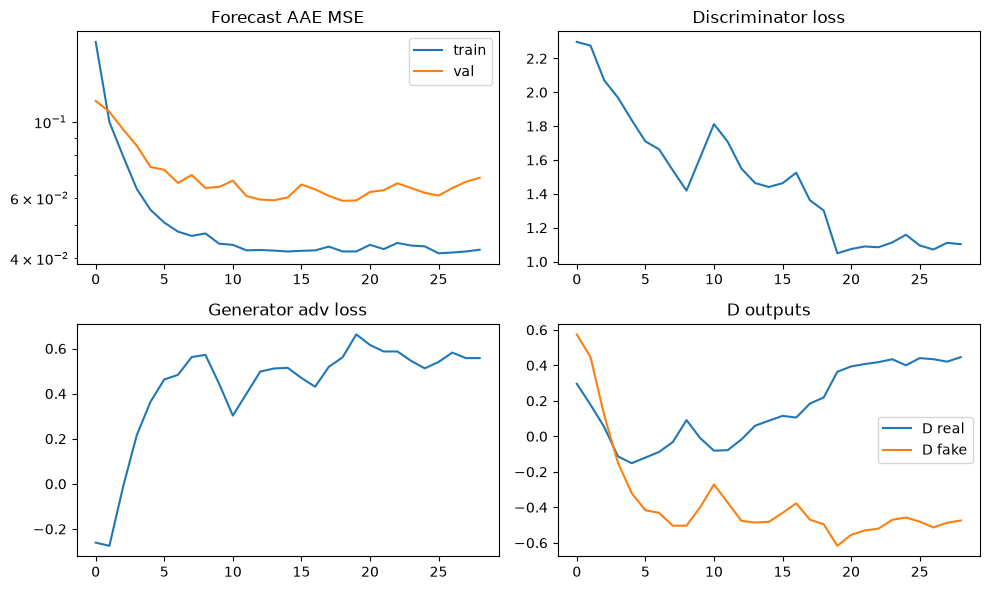


Evaluating on validation...

Validation: ROC-AUC=0.2627, PR-AUC=0.2696
Test:       ROC-AUC=0.9788, PR-AUC=0.9682

Thresholds:
  mu+2sigma: 0.083367
  Best percentile p85: 0.068350 (val F1=0.1376)

Test F1 @ mu+2sigma: 0.7385
Test F1 @ p85: 0.9494


In [19]:
# ============================================================
# TRAIN & EVALUATE: FORECASTING AAE (64->64 + Adversarial)
# ============================================================
print("=" * 60)
print("FORECASTING AAE (64 -> 64 + Adversarial)")
print("=" * 60)

fc_aae_model, fc_aae_disc, fc_aae_hist, fc_aae_best_val = train_forecast_aae(
    None, None, forecast_train_loader, forecast_val_loader, tag="Forecast AAE", seed=SEED
)

# Save checkpoint
torch.save({
    "model_state": fc_aae_model.state_dict(),
    "discriminator_state": fc_aae_disc.state_dict(),
    "history": fc_aae_hist,
    "config": {"window_len": WINDOW_LEN, "forecast_half": FORECAST_HALF,
               "objective": "forecasting_aae", "enc_channels": list(ENC_CHANNELS),
               "batch_size": BATCH_SIZE, "lr_G": LR_G_AAE, "lr_D": LR_D_AAE,
               "lambda_adv": LAMBDA_ADV, "betas": list(BETAS_AAE),
               "epochs_run": len(fc_aae_hist["train_mse"]), "best_val": fc_aae_best_val}
}, PROJECT_ROOT / "fc_aae.pt")
print("Saved -> fc_aae.pt")

# Plot training curves
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()
axes[0].plot(fc_aae_hist["train_mse"], label="train"); axes[0].plot(fc_aae_hist["val_mse"], label="val")
axes[0].set_yscale("log"); axes[0].set_title("Forecast AAE MSE"); axes[0].legend()
axes[1].plot(fc_aae_hist["loss_D"], label="D loss"); axes[1].set_title("Discriminator loss")
axes[2].plot(fc_aae_hist["loss_G_adv"], label="G adv"); axes[2].set_title("Generator adv loss")
axes[3].plot(fc_aae_hist["d_real"], label="D real"); axes[3].plot(fc_aae_hist["d_fake"], label="D fake")
axes[3].set_title("D outputs"); axes[3].legend()
plt.tight_layout()
plt.show()

# Evaluate on validation
print("\nEvaluating on validation...")
fc_aae_val_norm_err, fc_aae_val_anom_err = evaluate_model(
    fc_aae_model, forecast_val_loader, fc_slow_val_loader, DEVICE, mode='forecasting'
)

fc_aae_test_norm_err, fc_aae_test_anom_err = evaluate_model(
    fc_aae_model,
    DataLoader(TensorDataset(X_test_in, X_test_tg), batch_size=BATCH_SIZE, shuffle=False),
    fc_slow_test_loader, DEVICE, mode='forecasting'
)

# Metrics
fc_aae_val_metrics = compute_metrics(fc_aae_val_norm_err, fc_aae_val_anom_err)
fc_aae_test_metrics = compute_metrics(fc_aae_test_norm_err, fc_aae_test_anom_err)

print(f"\nValidation: ROC-AUC={fc_aae_val_metrics['roc_auc']:.4f}, PR-AUC={fc_aae_val_metrics['pr_auc']:.4f}")
print(f"Test:       ROC-AUC={fc_aae_test_metrics['roc_auc']:.4f}, PR-AUC={fc_aae_test_metrics['pr_auc']:.4f}")

# Threshold selection
fc_aae_thresh_pct, fc_aae_best_p, fc_aae_best_f1 = percentile_threshold_selection(fc_aae_val_norm_err, fc_aae_val_anom_err)
fc_aae_thresh_mu2 = mu_sigma_threshold(fc_aae_val_norm_err)

print(f"\nThresholds:")
print(f"  mu+2sigma: {fc_aae_thresh_mu2:.6f}")
print(f"  Best percentile p{fc_aae_best_p}: {fc_aae_thresh_pct:.6f} (val F1={fc_aae_best_f1:.4f})")

# Test with selected thresholds
fc_aae_test_mu2 = compute_metrics(fc_aae_test_norm_err, fc_aae_test_anom_err, fc_aae_thresh_mu2)
fc_aae_test_pct = compute_metrics(fc_aae_test_norm_err, fc_aae_test_anom_err, fc_aae_thresh_pct)

print(f"\nTest F1 @ mu+2sigma: {fc_aae_test_mu2['f1']:.4f}")
print(f"Test F1 @ p{fc_aae_best_p}: {fc_aae_test_pct['f1']:.4f}")

# Store results
fc_aae_results = {
    "tag": "Forecasting AAE",
    "val_roc_auc": fc_aae_val_metrics['roc_auc'],
    "val_pr_auc": fc_aae_val_metrics['pr_auc'],
    "test_roc_auc": fc_aae_test_metrics['roc_auc'],
    "test_pr_auc": fc_aae_test_metrics['pr_auc'],
    "threshold_mu2": fc_aae_thresh_mu2,
    "threshold_pct": fc_aae_thresh_pct,
    "best_p": fc_aae_best_p,
    "test_f1_mu2": fc_aae_test_mu2['f1'],
    "test_f1_pct": fc_aae_test_pct['f1'],
}

FINAL COMPARISON - ALL MODELS
                 Model | Val ROC |  Val PR | Test ROC | Test PR |  F1 mu2 |  F1 pct |   pct
----------------------------------------------------------------------------------------------------
     Reconstruction AE |  0.0104 |  0.2164 |   0.9565 |  0.9550 |  0.7344 |  0.9115 | p 80
        Forecasting AE |  0.3492 |  0.3089 |   0.9647 |  0.9561 |  0.8936 |  0.7731 | p 80
                   AAE |  0.0057 |  0.2161 |   0.9454 |  0.9518 |  0.9385 |  0.8902 | p 80
       Forecasting AAE |  0.2627 |  0.2696 |   0.9788 |  0.9682 |  0.7385 |  0.9494 | p 85


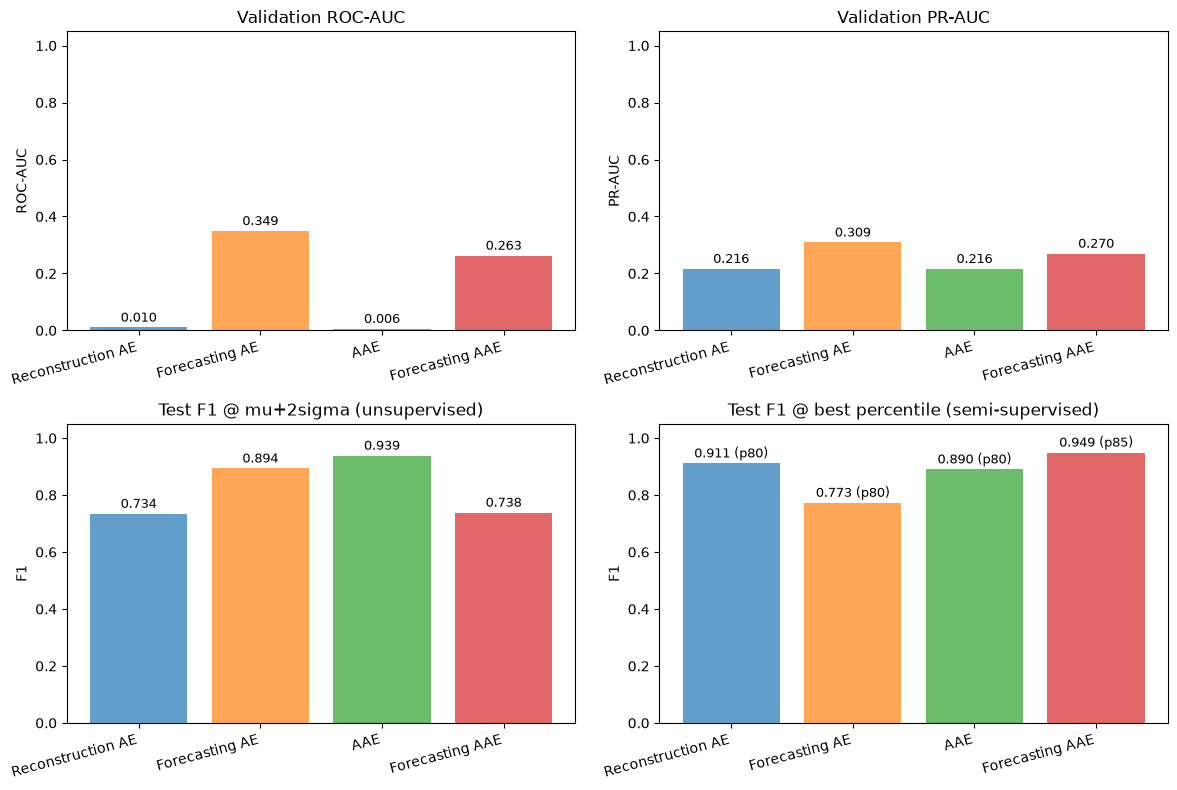


KEY FINDINGS:
Best Test ROC-AUC: Forecasting AAE (0.9788)
Best Test PR-AUC:  Forecasting AAE (0.9682)
Best F1 @ mu+2sigma: AAE (0.9385)
Best F1 @ pct:      Forecasting AAE (0.9494 at 85)

--- Delta vs Reconstruction AE ---
        Forecasting AE: dROC=+0.0082, dPR=+0.0012, dF1_mu2=+0.1592, dF1_pct=-0.1384
                   AAE: dROC=-0.0112, dPR=-0.0032, dF1_mu2=+0.2041, dF1_pct=-0.0212
       Forecasting AAE: dROC=+0.0223, dPR=+0.0133, dF1_mu2=+0.0041, dF1_pct=+0.0379

Saved summary -> c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\model_comparison_summary.json

Done!


In [20]:
# ============================================================
# FINAL COMPARISON & SUMMARY
# ============================================================
print("=" * 60)
print("FINAL COMPARISON - ALL MODELS")
print("=" * 60)

# Collect all results
all_results = [recon_results, forecast_results, aae_results, fc_aae_results]

# Print comparison table
print(f"{'Model':>22s} | {'Val ROC':>7s} | {'Val PR':>7s} | {'Test ROC':>8s} | {'Test PR':>7s} | "
      f"{'F1 mu2':>7s} | {'F1 pct':>7s} | {'pct':>5s}")
print("-" * 100)
for r in all_results:
    print(f"{r['tag']:>22s} | {r['val_roc_auc']:7.4f} | {r['val_pr_auc']:7.4f} | "
          f"{r['test_roc_auc']:8.4f} | {r['test_pr_auc']:7.4f} | "
          f"{r['test_f1_mu2']:7.4f} | {r['test_f1_pct']:7.4f} | p{r['best_p']:>3d}")

# Bar chart comparison
labels = [r["tag"] for r in all_results]
val_roc = [r["val_roc_auc"] for r in all_results]
val_pr = [r["val_pr_auc"] for r in all_results]
test_roc = [r["test_roc_auc"] for r in all_results]
test_pr = [r["test_pr_auc"] for r in all_results]
f1_mu2 = [r["test_f1_mu2"] for r in all_results]
f1_pct = [r["test_f1_pct"] for r in all_results]
pct_rules = [f"p{r['best_p']}" for r in all_results]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# Validation ROC-AUC
bars = axes[0].bar(labels, val_roc, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], alpha=0.7)
axes[0].set_title("Validation ROC-AUC")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0, 1.05)
for bar, val in zip(bars, val_roc):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{val:.3f}", ha='center', va='bottom', fontsize=9)
plt.setp(axes[0].get_xticklabels(), rotation=15, ha='right')

# Validation PR-AUC
bars = axes[1].bar(labels, val_pr, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], alpha=0.7)
axes[1].set_title("Validation PR-AUC")
axes[1].set_ylabel("PR-AUC")
axes[1].set_ylim(0, 1.05)
for bar, val in zip(bars, val_pr):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{val:.3f}", ha='center', va='bottom', fontsize=9)
plt.setp(axes[1].get_xticklabels(), rotation=15, ha='right')

# Test F1 mu+2sigma
bars = axes[2].bar(labels, f1_mu2, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], alpha=0.7)
axes[2].set_title("Test F1 @ mu+2sigma (unsupervised)")
axes[2].set_ylabel("F1")
axes[2].set_ylim(0, 1.05)
for bar, val in zip(bars, f1_mu2):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{val:.3f}", ha='center', va='bottom', fontsize=9)
plt.setp(axes[2].get_xticklabels(), rotation=15, ha='right')

# Test F1 best percentile
bars = axes[3].bar(labels, f1_pct, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], alpha=0.7)
axes[3].set_title("Test F1 @ best percentile (semi-supervised)")
axes[3].set_ylabel("F1")
axes[3].set_ylim(0, 1.05)
for bar, val, p in zip(bars, f1_pct, pct_rules):
    axes[3].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{val:.3f} ({p})", ha='center', va='bottom', fontsize=9)
plt.setp(axes[3].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.show()

# Summary
print("\n" + "=" * 60)
print("KEY FINDINGS:")
print("=" * 60)

roc_winner = max(all_results, key=lambda r: r["test_roc_auc"])
pr_winner = max(all_results, key=lambda r: r["test_pr_auc"])
f1_mu2_winner = max(all_results, key=lambda r: r["test_f1_mu2"])
f1_pct_winner = max(all_results, key=lambda r: r["test_f1_pct"])

print(f"Best Test ROC-AUC: {roc_winner['tag']} ({roc_winner['test_roc_auc']:.4f})")
print(f"Best Test PR-AUC:  {pr_winner['tag']} ({pr_winner['test_pr_auc']:.4f})")
print(f"Best F1 @ mu+2sigma: {f1_mu2_winner['tag']} ({f1_mu2_winner['test_f1_mu2']:.4f})")
print(f"Best F1 @ pct:      {f1_pct_winner['tag']} ({f1_pct_winner['test_f1_pct']:.4f} at {f1_pct_winner['best_p']})")

# Delta analysis
print("\n--- Delta vs Reconstruction AE ---")
for r in all_results[1:]:
    d_roc = r["test_roc_auc"] - recon_results["test_roc_auc"]
    d_pr = r["test_pr_auc"] - recon_results["test_pr_auc"]
    d_f1_mu2 = r["test_f1_mu2"] - recon_results["test_f1_mu2"]
    d_f1_pct = r["test_f1_pct"] - recon_results["test_f1_pct"]
    print(f"  {r['tag']:>20s}: dROC={d_roc:+.4f}, dPR={d_pr:+.4f}, dF1_mu2={d_f1_mu2:+.4f}, dF1_pct={d_f1_pct:+.4f}")

# Save summary JSON
summary = {
    "config": {
        "window_len": WINDOW_LEN, "forecast_half": FORECAST_HALF,
        "enc_channels": list(ENC_CHANNELS), "batch_size": BATCH_SIZE,
        "epochs_cap": EPOCHS, "patience": PATIENCE, "lr": LEARNING_RATE,
        "aae_lambda_adv": LAMBDA_ADV, "aae_lr_G": LR_G_AAE, "aae_lr_D": LR_D_AAE,
        "data": f"KukaNormal (action dropped, {n_features} features), chronological split",
        "slow_split": f"first {SLOW_VAL_FRAC:.0%} slow windows for threshold validation; remaining for final test",
        "n_slow_val": int(len(W_slow_val)), "n_slow_test": int(len(W_slow_test)),
        "n_val_normal": int(len(W_val)), "n_test_normal": int(len(W_test)),
    },
    "models": {
        r["tag"]: {
            "val_roc_auc": r["val_roc_auc"],
            "val_pr_auc": r["val_pr_auc"],
            "test_roc_auc": r["test_roc_auc"],
            "test_pr_auc": r["test_pr_auc"],
            "threshold_mu2": r["threshold_mu2"],
            "threshold_pct": r["threshold_pct"],
            "best_percentile": r["best_p"],
            "test_f1_mu2": r["test_f1_mu2"],
            "test_f1_pct": r["test_f1_pct"],
        } for r in all_results
    }
}

with open(PROJECT_ROOT / "model_comparison_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(f"\nSaved summary -> {PROJECT_ROOT / 'model_comparison_summary.json'}")

print("\nDone!")